Here is a simple example code for device fitting using a multilayer perceptron model.
This code demonstrates the implementation of a Multilayer Perceptron (MLP) using PyTorch, a popular deep learning framework. Let's break down the key components of this code.

In [1]:
import os
import sys
import json

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import LayerNorm
from torchvision import transforms, datasets, utils
import matplotlib.pyplot as plt
import numpy as np
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import pandas as pd
from tqdm import tqdm
import random
import torch.nn.functional as F
from sklearn.model_selection import train_test_split, GridSearchCV, ParameterGrid
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler


from torch.utils.data import TensorDataset, DataLoader
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv


The code snippet demonstrates the selection of the computational device for running the MLP (Multilayer Perceptron) network.
Device Allocation:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu"): This line of code assigns the computational device to the variable device. If a GPU is available, it selects the GPU (cuda:0); otherwise, it defaults to the CPU (cpu).
Printing Device Information:
print("using {} device.".format(device)): This prints a message indicating the device being utilized for computation.

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("using {} device.".format(device))

using cpu device.


The code snippet demonstrates reading data from an Excel file into a Python environment using the Pandas library.
Excel File Import:
excel_file = '../data/carbon/pfet.xlsx': Specifies the file path (pfet.xlsx) of the Excel file containing the data.
Pandas DataFrame Creation:
df = pd.read_excel(excel_file): Utilizes Pandas' read_excel function to load the Excel file into a Pandas DataFrame named df. This function reads the Excel file's contents and stores them in a tabular format.
Data Verification:
print(df.head()): Displays the first few rows of the loaded DataFrame using the head() method. This step helps verify the successful import of data by showing the initial rows of the DataFrame, ensuring that the data is correctly read and structured.

In [3]:
#Excel File Import
csv_file = 'Silicon_Dataset.csv'
df = pd.read_csv(csv_file)
df = df.apply(pd.to_numeric)

print(df.head())

    Lg  Lch    Tox          Nsub         PeakV  Vds       Vgs            Id
0  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -1.000000  3.220000e-16
1  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.974747  3.220000e-16
2  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.949495  3.210000e-16
3  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.924242  3.230000e-16
4  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.898990  3.230000e-16


This code snippet focuses on data preparation steps necessary before training the Multilayer Perceptron (MLP) model.
Input and Output Extraction:
Specifies the columns representing input features based on their column names in the dataset.
Defines the output column ('ids') indicating the target output (e.g., current) from the dataset.
Conversion to PyTorch Tensors:
Converts the selected input columns and output column into PyTorch tensors. This step transforms the input data into a format suitable for feeding into the neural network.
Data Transformation:
Take the logarithm of the output data to narrow the data range. This transformation might be employed to normalize or preprocess the output data, ensuring better convergence during training or meeting specific requirements of the model.

In [4]:

# Assuming 'df' is your DataFrame and 'Id' is the target column
input_columns = ['Lg', 'Lch', 'Tox', 'Nsub', 'PeakV', 'Vds', 'Vgs']
output_column = 'Id'

# Prepare the data
X = df[input_columns].values
Y = df[output_column].values


This section of code mainly used do feature selection and show the importance of each different feature's relationship and importance between the factors.

In [5]:
# # Splitting the data into train and test sets
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# # Train a Random Forest Regressor model
# rf_model = RandomForestRegressor(random_state=42)
# rf_model.fit(X_train, Y_train)

# # Compute the baseline Mean Squared Error
# Y_pred = rf_model.predict(X_test)
# baseline_mse = mean_squared_error(Y_test, Y_pred)
# print(f"Baseline Mean Squared Error: {baseline_mse:.4f}")

# # Get feature importances
# feature_importances = rf_model.feature_importances_

# # Display feature importance
# feature_names = X_test.columns.tolist()
# importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
# importance_df = importance_df.sort_values(by='Importance', ascending=False)

# print(importance_df)

# # Plot feature importance
# plt.figure(figsize=(10, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'])
# plt.xlabel('Importance')
# plt.ylabel('Feature')
# plt.title('Feature Importance')
# plt.gca().invert_yaxis()
# plt.show()

This section of the code snippet focuses on partitioning the available data into separate sets for training and testing the MLP (Multilayer Perceptron) model.
Splitting the Dataset:
These calculations aim to appropriately divide the dataset into two distinct portions:
Training Set: Comprising 90% of the data, reserved for training the MLP model. It includes input-output pairs used to optimize the model's parameters.
Testing Set: Consisting of the remaining 10% of the data. This set remains unseen during training and is employed solely for evaluating the model's performance on unseen data, assessing its generalization capability.

In [6]:

# Data Sampling: Pick the first 1000 samples
sample_num = 1000
X = X[:sample_num]
Y = Y[:sample_num]

# Normalize the data
scaler_X = StandardScaler()
scaler_Y = StandardScaler()

X = scaler_X.fit_transform(X)  # Normalize input features
Y = scaler_Y.fit_transform(Y.reshape(-1, 1)).flatten()  # Normalize output values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.float32)
Y = torch.tensor(Y, dtype=torch.float32)

# Take the logarithm of the output data
Y = -0.1 * torch.where(Y < 0, torch.log(-Y), torch.log(Y))

# Here print the input and output separately
print(X)
print(Y)



tensor([[-1.3878e-17, -2.7756e-17, -8.1650e-01,  ...,  1.0000e+00,
         -2.7756e-17, -1.7148e+00],
        [-1.3878e-17, -2.7756e-17, -8.1650e-01,  ...,  1.0000e+00,
         -2.7756e-17, -1.6802e+00],
        [-1.3878e-17, -2.7756e-17, -8.1650e-01,  ...,  1.0000e+00,
         -2.7756e-17, -1.6455e+00],
        ...,
        [-1.3878e-17, -2.7756e-17,  1.2247e+00,  ..., -1.0000e+00,
         -2.7756e-17,  1.6455e+00],
        [-1.3878e-17, -2.7756e-17,  1.2247e+00,  ..., -1.0000e+00,
         -2.7756e-17,  1.6802e+00],
        [-1.3878e-17, -2.7756e-17,  1.2247e+00,  ..., -1.0000e+00,
         -2.7756e-17,  1.7148e+00]])
tensor([ 0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,
         0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,
         0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,
         0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,  0.0775,
         0.0775,  0.0775,  0.0775,  0.0775,  0.0

# Using GCN model (CNN)
## GatGCN Framework

In [7]:
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch.nn import LayerNorm
import torch.nn.functional as F
import torch

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Convert the data to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float)
y_train = torch.tensor(y_train, dtype=torch.float)
X_test = torch.tensor(X_test, dtype=torch.float)
y_test = torch.tensor(y_test, dtype=torch.float)

# Create a graph data object (example with fully connected graph)
train_edge_index = torch.combinations(torch.arange(X_train.size(0)), r=2).t().contiguous()
test_edge_index = torch.combinations(torch.arange(X_test.size(0)), r=2).t().contiguous()
data = Data(x=X_train, edge_index=train_edge_index, y=y_train)

class FatGCN(torch.nn.Module):
    def __init__(self, in_channels, num_classes):
        super(FatGCN, self).__init__()

        # GCN layers (5 layers)
        self.gcn_layers = torch.nn.ModuleList([
            GCNConv(in_channels, 128),
            GCNConv(128, 128),
            GCNConv(128, 256),
            GCNConv(256, 256),
            GCNConv(256, 512),
        ])

        # Layer Normalization for each GCN layer
        self.norm_layers = torch.nn.ModuleList([
            LayerNorm(128),
            LayerNorm(128),
            LayerNorm(256),
            LayerNorm(256),
            LayerNorm(512),
        ])

        # MLP layers (6 layers)
        self.mlp_layers = torch.nn.ModuleList([
            torch.nn.Linear(512, 512),
            torch.nn.Linear(512, 256),
            torch.nn.Linear(256, 256),
            torch.nn.Linear(256, 128),
            torch.nn.Linear(128, 128),
            torch.nn.Linear(128, num_classes)
        ])

        # Layer Normalization for each MLP layer
        self.mlp_norms = torch.nn.ModuleList([
            LayerNorm(512),
            LayerNorm(256),
            LayerNorm(256),
            LayerNorm(128),
            LayerNorm(128),
        ])

    def forward(self, x, edge_index):
        # GCN layers with LayerNorm
        for i, gcn in enumerate(self.gcn_layers):
            x = gcn(x, edge_index)
            x = self.norm_layers[i](x)
            x = F.relu(x)

        # MLP layers with LayerNorm
        for i, mlp in enumerate(self.mlp_layers[:-1]):  # Exclude last layer
            x = mlp(x)
            x = self.mlp_norms[i](x)
            x = F.relu(x)

        # Final layer without activation
        x = self.mlp_layers[-1](x)

        return x

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Initialize model
model = FatGCN(in_channels=X_train.size(1), num_classes=1).to(device)

# Function to calculate the number of trainable parameters
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Print the number of trainable parameters in the FatGCN model
num_params = count_parameters(model)
print(f'The FatGCN model has {num_params:,} trainable parameters.')



The FatGCN model has 762,369 trainable parameters.


C:\Users\Lava\AppData\Local\Temp\ipykernel_32700\2074012846.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_train = torch.tensor(X_train, dtype=torch.float)
C:\Users\Lava\AppData\Local\Temp\ipykernel_32700\2074012846.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_train, dtype=torch.float)
C:\Users\Lava\AppData\Local\Temp\ipykernel_32700\2074012846.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_test = torch.tensor(X_test, dtype=torch.float)
C:\Users\Lava\AppData\Local\Temp\ipykernel_32700\20740

In [8]:
# Move data to device
data = data.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = torch.nn.L1Loss()  # Use L1Loss for MAE

# Initialize val_mae_list to store validation MAE values
val_mae_list = []

# Training loop
epochs = 50
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    # Forward pass
    out = model(data.x, data.edge_index)
    
    # Compute loss
    loss = criterion(out.squeeze(), data.y)
    loss.backward()
    optimizer.step()
    
    # Validation
    model.eval()
    with torch.no_grad():
        test_data = Data(x=X_test, edge_index=test_edge_index, y=y_test).to(device)
        pred = model(test_data.x, test_data.edge_index).squeeze()
        val_mae = criterion(pred, test_data.y).item()  # Compute MAE for validation
    
    # Append validation MAE to the list
    val_mae_list.append(val_mae)
    
    print(f'Epoch {epoch+1}, Loss: {loss.item():.6f}, Validation MAE: {val_mae:.6f}')

Epoch 1, Loss: 0.364167, Validation MAE: 1.433346
Epoch 2, Loss: 1.352488, Validation MAE: 0.618174
Epoch 3, Loss: 0.587502, Validation MAE: 0.050887
Epoch 4, Loss: 0.066604, Validation MAE: 0.039901
Epoch 5, Loss: 0.036135, Validation MAE: 0.180525
Epoch 6, Loss: 0.191253, Validation MAE: 0.113091
Epoch 7, Loss: 0.118956, Validation MAE: 0.087631
Epoch 8, Loss: 0.082189, Validation MAE: 0.097755
Epoch 9, Loss: 0.092302, Validation MAE: 0.043422
Epoch 10, Loss: 0.043271, Validation MAE: 0.060952
Epoch 11, Loss: 0.055547, Validation MAE: 0.051820
Epoch 12, Loss: 0.052006, Validation MAE: 0.056848
Epoch 13, Loss: 0.051540, Validation MAE: 0.045199
Epoch 14, Loss: 0.044384, Validation MAE: 0.061673
Epoch 15, Loss: 0.056926, Validation MAE: 0.046972
Epoch 16, Loss: 0.042931, Validation MAE: 0.081083
Epoch 17, Loss: 0.082756, Validation MAE: 0.074188
Epoch 18, Loss: 0.074980, Validation MAE: 0.049835
Epoch 19, Loss: 0.045880, Validation MAE: 0.054411
Epoch 20, Loss: 0.050417, Validation MAE

### Visualization of training process

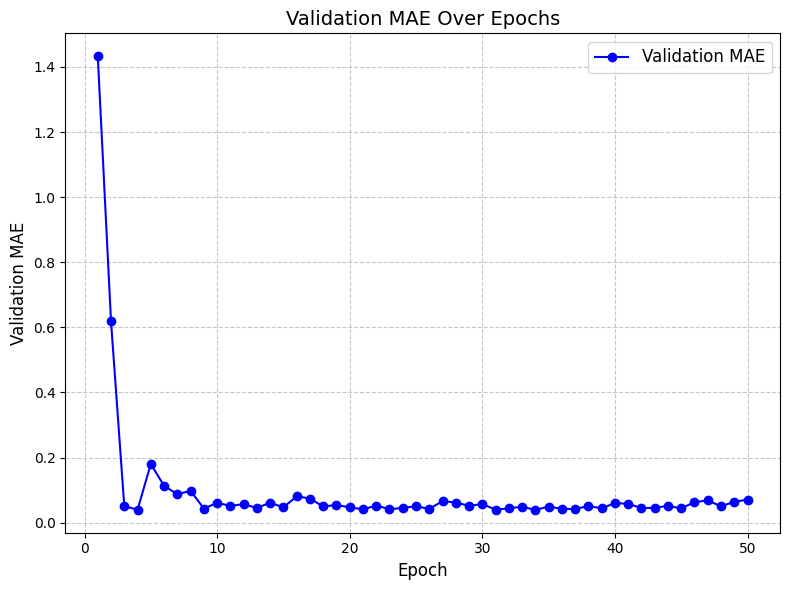

In [9]:
# Plot the change of validation MAE over epochs
plt.figure(figsize=(8, 6))
plt.plot(range(1, epochs + 1), val_mae_list, label='Validation MAE', color='blue', marker='o', linestyle='-')

# Add labels and title
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Validation MAE', fontsize=12)
plt.title('Validation MAE Over Epochs', fontsize=14)

# Add gridlines
plt.grid(axis='both', linestyle='--', alpha=0.7)

# Add legend
plt.legend(fontsize=12)

# Show the plot
plt.tight_layout()
plt.show()